In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42

print("All libraries imported successfully!")


All libraries imported successfully!


In [10]:

# Load the diabetes dataset
diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("\nFeature names:")
print(X.columns.tolist())

display(X.head())


Dataset loaded successfully!
Number of rows: 442
Number of features: 10

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [11]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Create and train the Gradient Boosting model
model = GradientBoostingRegressor(random_state=RANDOM_STATE)
model.fit(X_train, y_train)

# Evaluate the model
predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Model training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.4f}")


Model training completed!
Training samples: 353
Testing samples: 89
Mean Squared Error: 2887.23
R² Score: 0.4550


In [12]:
# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for test data
shap_values = explainer(X_test)

print("SHAP explanations generated successfully!")
print("Test samples explained:", X_test.shape[0])
print("Features analyzed:", X_test.shape[1])

SHAP explanations generated successfully!
Test samples explained: 89
Features analyzed: 10


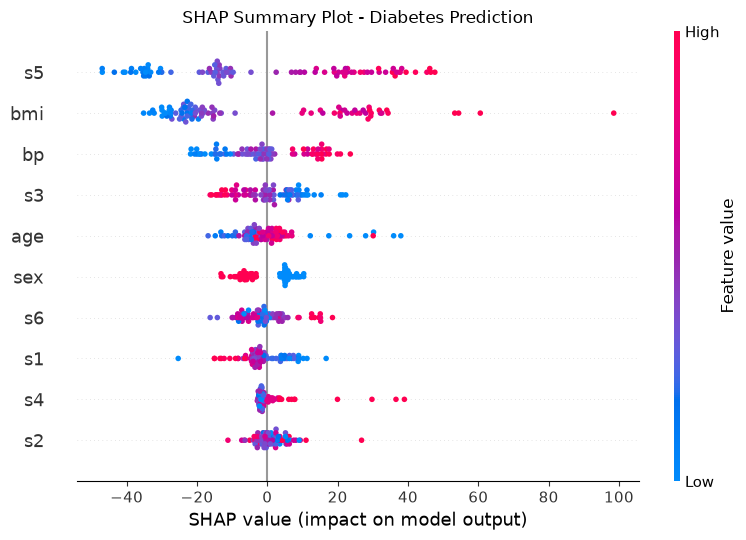

In [13]:
# Generate SHAP summary plot
shap.plots.beeswarm(shap_values, show=False)

plt.title("SHAP Summary Plot - Diabetes Prediction")
plt.tight_layout()
plt.show()

Individual Prediction Explanation
---------------------------------
Sample Index: 0
Predicted Diabetes Progression: 161.29
Actual Value: 219.00


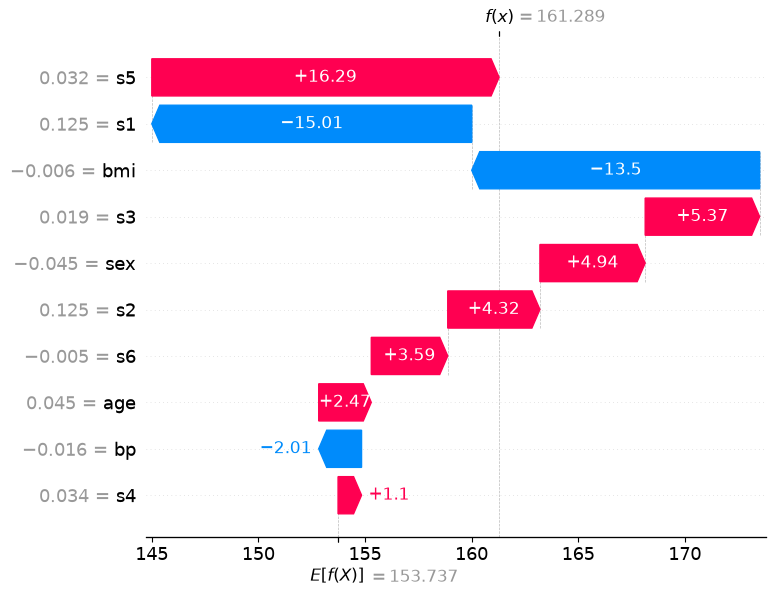

In [14]:
# Select one test sample
sample_index = 0
sample = X_test.iloc[[sample_index]]

# Predict the selected sample
predicted_value = model.predict(sample)[0]

print("Individual Prediction Explanation")
print("---------------------------------")
print("Sample Index:", sample_index)
print(f"Predicted Diabetes Progression: {predicted_value:.2f}")
print(f"Actual Value: {y_test.iloc[sample_index]:.2f}")

# Explain this individual prediction using SHAP
sample_shap_values = explainer(sample)

shap.plots.waterfall(sample_shap_values[0])

In [ ]:
from pathlib import Path

# Create output folder
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save actual and predicted values
results = pd.DataFrame({
    "Actual_Value": y_test.to_numpy(),
    "Predicted_Value": predictions
})

results.to_csv(OUTPUT_DIR / "predictions.csv", index=False)

# Save SHAP summary plot
plt.figure()
shap.plots.beeswarm(shap_values, show=False)
plt.title("SHAP Summary Plot - Diabetes Prediction")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.close()

# Save individual prediction explanation
shap.plots.waterfall(sample_shap_values[0], show=False)
plt.savefig(OUTPUT_DIR / "individual_explanation.png", dpi=300, bbox_inches="tight")
plt.close()

print("Project outputs saved successfully!")
print("Saved files:")
for file in OUTPUT_DIR.iterdir():
    print("-", file)